In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [2]:
import kagglehub

Face = kagglehub.dataset_download("jangedoo/utkface-new")

print("Path to dataset files:", Face)

Using Colab cache for faster access to the 'utkface-new' dataset.
Path to dataset files: /kaggle/input/utkface-new


In [3]:
import os

data = []

for root, dirs, filenames in os.walk(Face):
    for file in filenames:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            data.append(os.path.join(root, file))

print("Number of images:", len(data))

Number of images: 66976


In [4]:
print(data[:5])

['/kaggle/input/utkface-new/UTKFace/26_0_2_20170104023102422.jpg.chip.jpg', '/kaggle/input/utkface-new/UTKFace/22_1_1_20170112233644761.jpg.chip.jpg', '/kaggle/input/utkface-new/UTKFace/21_1_3_20170105003215901.jpg.chip.jpg', '/kaggle/input/utkface-new/UTKFace/28_0_0_20170117180555824.jpg.chip.jpg', '/kaggle/input/utkface-new/UTKFace/17_1_4_20170103222931966.jpg.chip.jpg']


In [5]:
# create table and sepreat the ages
import os
import pandas as pd

ages = []

for root, dirs, filenames in os.walk(Face):
    for file in filenames:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            try:
                age = int(file.split("_")[0])
                path = os.path.join(root, file)
                ages.append([path, age])
            except ValueError:
                continue

df = pd.DataFrame(ages, columns=["filename", "age"])

In [6]:
print(df.head())

                                            filename  age
0  /kaggle/input/utkface-new/UTKFace/26_0_2_20170...   26
1  /kaggle/input/utkface-new/UTKFace/22_1_1_20170...   22
2  /kaggle/input/utkface-new/UTKFace/21_1_3_20170...   21
3  /kaggle/input/utkface-new/UTKFace/28_0_0_20170...   28
4  /kaggle/input/utkface-new/UTKFace/17_1_4_20170...   17


In [7]:
print("Dataset shape:", df.shape)

Dataset shape: (66976, 2)


In [8]:
print(df["age"].describe())

count    66976.000000
mean        32.169792
std         21.502316
min          1.000000
25%         18.000000
50%         28.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64


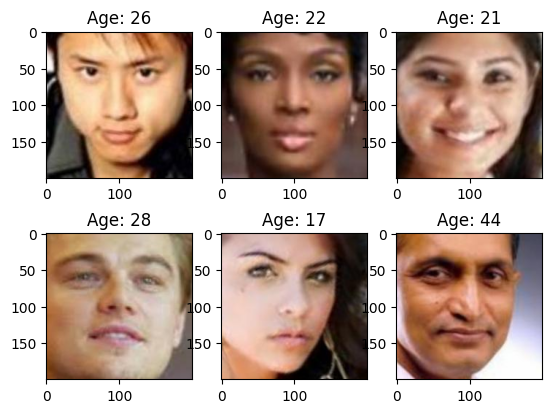

In [9]:
# presint sample of img

for i in range(6):
    img = Image.open(
        os.path.join(Face, df.iloc[i]["filename"])
    ).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title("Age: " + str(df.iloc[i]["age"]))

plt.show()

In [10]:
# size of img
img.size

(200, 200)

In [11]:
# color of img and our data is colors img not black and white
img.mode

'RGB'

In [12]:
# change the age to group age
def age_group(age):
    if age <= 12:
        return 0
    elif age <= 19:
        return 1
    elif age <= 39:
        return 2
    elif age <= 59:
        return 3
    else:
        return 4

df["age_group"] = df["age"].apply(age_group)

In [13]:
df["age_group"].value_counts().sort_index()

,count
age_group,
0,13336
1,4178
2,28864
3,12314
4,8284


In [14]:
train_df, test_df = train_test_split(df,
    test_size=0.20, random_state=42,
    # to balance the age data in each split
    stratify=df["age_group"])

In [15]:
def load_images(dataframe):
    images = []

    for file in dataframe["filename"]:
        # open the img
        img = Image.open(file).convert("RGB")
        # change the size becouse oure size is big and take time in train
        img = img.resize((48, 48))
        # converts an img into an array
        images.append(np.array(img))
    return np.array(images, dtype="float32") / 255.0

In [16]:
X_train = load_images(train_df)
X_test = load_images(test_df)

In [17]:
y_train = train_df["age_group"].to_numpy()
y_test = test_df["age_group"].to_numpy()

In [18]:
# number of img , size , number of colors
X_train.shape

(53580, 48, 48, 3)

In [19]:
X_test.shape

(13396, 48, 48, 3)

In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPool2D

# Step 2
model = Sequential()

# Feature Extraction 2D
model.add(Conv2D(# number of fiter lear
                 filters=30,
                 # size of filter 3*3
                 kernel_size=(3, 3),
                 activation='relu',
                 input_shape=(48, 48, 3)))

model.add(Conv2D(filters=40,
                 kernel_size=3,
                 activation='relu'))

model.add(Conv2D(filters=50,
                 kernel_size=3,
                 activation='relu'))

# Connect 2D with 1D
model.add(Flatten())

# Classification 1D
# Converting results into probabilities
model.add(Dense(5, activation='softmax'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 46, 46, 30)     │           840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 44, 44, 40)     │        10,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 42, 42, 50)     │        18,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 88200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │       441,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 470,735 (1.80 MB)

 Trainable params: 470,735 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model.compile( # we have 5 cat and the labels are numbers from 0 to 4
    loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=10, validation_split=0.2)

Epoch 1/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.7079 - loss: 0.7615 - val_accuracy: 0.7873 - val_loss: 0.5717
Epoch 2/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.8350 - loss: 0.4456 - val_accuracy: 0.8510 - val_loss: 0.4227
Epoch 3/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.9017 - loss: 0.2803 - val_accuracy: 0.8892 - val_loss: 0.3366
Epoch 4/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.9396 - loss: 0.1760 - val_accuracy: 0.8907 - val_loss: 0.3478
Epoch 5/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.9612 - loss: 0.1214 - val_accuracy: 0.9077 - val_loss: 0.3326
Epoch 6/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.9719 - loss: 0.0901 - val_accuracy: 0.9329 - val_loss: 0.3029
Epoch 7/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.9788 - loss: 0.0703 - val_accuracy: 0.9359 - val_loss: 0.3248
Epoch 8/10
1340/1340 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.9827 - los

In [24]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

419/419 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9433 - loss: 0.4062


In [25]:
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.40615901350975037
Test Accuracy: 0.9433413147926331


In [26]:
y_pred = model.predict(X_test)
y_pred_classes = y_pred.argmax(axis=1)

419/419 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


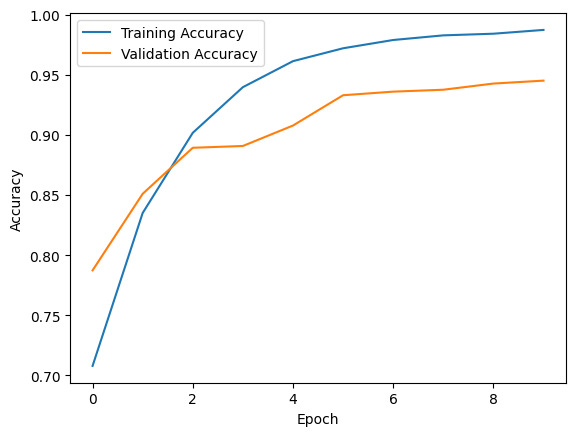

In [27]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

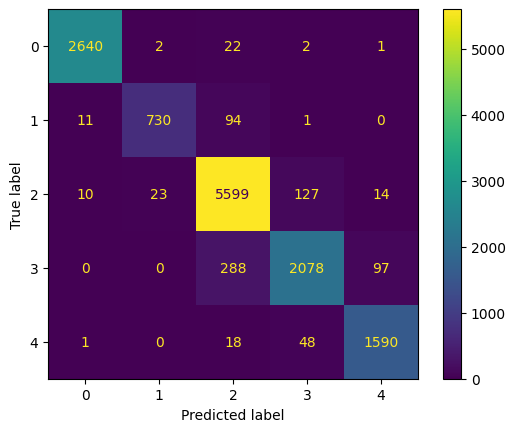

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_classes
)

plt.show()

In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2667
           1       0.97      0.87      0.92       836
           2       0.93      0.97      0.95      5773
           3       0.92      0.84      0.88      2463
           4       0.93      0.96      0.95      1657

    accuracy                           0.94     13396
   macro avg       0.95      0.93      0.94     13396
weighted avg       0.94      0.94      0.94     13396



In [30]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2667
           1       0.97      0.87      0.92       836
           2       0.93      0.97      0.95      5773
           3       0.92      0.84      0.88      2463
           4       0.93      0.96      0.95      1657

    accuracy                           0.94     13396
   macro avg       0.95      0.93      0.94     13396
weighted avg       0.94      0.94      0.94     13396



In [31]:
from tensorflow.keras.layers import  Dropout

model2 = Sequential()

# Feature Extraction
model2.add(Conv2D(
    filters=30,
    kernel_size=(3, 3),
    activation='relu',
    input_shape=(48, 48, 3)
))

model2.add(MaxPool2D(pool_size=(2, 2)))

model2.add(Conv2D(
    filters=40,
    kernel_size=3,
    activation='relu'
))

model2.add(MaxPool2D(pool_size=(2, 2)))

model2.add(Conv2D(
    filters=50,
    kernel_size=3,
    activation='relu'
))

# Connect 2D with 1D
model2.add(Flatten())

# Classification
model2.add(Dense(100, activation='relu'))
model2.add(Dropout(0.3))

# Output: 5 age groups
model2.add(Dense(5, activation='softmax'))

model2.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 46, 46, 30)     │           840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 30)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 21, 21, 40)     │        10,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 40)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 50)       │        18,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │       320,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           505 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 350,335 (1.34 MB)

 Trainable params: 350,335 (1.34 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model2.compile(
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

In [33]:
test_loss, test_accuracy = model2.evaluate(X_test, y_test)

419/419 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.2330 - loss: 1.6040


In [34]:
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 1.6040496826171875
Test Accuracy: 0.23297999799251556


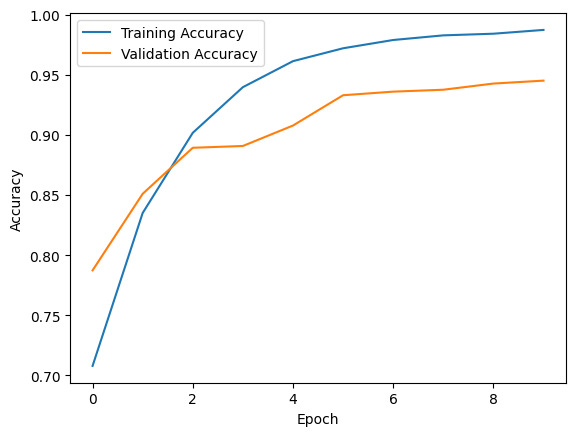

In [35]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [36]:
y_pred2 = model2.predict(X_test)
y_pred_classes2 = y_pred2.argmax(axis=1)

419/419 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [37]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred_classes2)

print("MSE:", mse)

MSE: 2.6354135562854584


In [38]:
print(classification_report(y_test, y_pred_classes2))

              precision    recall  f1-score   support

           0       0.16      0.04      0.06      2667
           1       0.06      0.08      0.07       836
           2       0.54      0.22      0.32      5773
           3       0.18      0.68      0.28      2463
           4       0.00      0.00      0.00      1657

    accuracy                           0.23     13396
   macro avg       0.19      0.20      0.15     13396
weighted avg       0.30      0.23      0.20     13396



In [44]:
model.save("best_age_regression_model.keras")